# Module 5 — Worksheet 3: Decision Tree Hyperparameters and Grid Search
**ISA 591 — Introduction to Data Mining in Business**

**Goal:** Understand how to control tree complexity and select hyperparameters using `GridSearchCV`.

Work through the code in order. Complete the short `TODO` exercises and answer the interpretation questions.

## 1. Load and prepare the Telco churn data

We want to predict whether a customer will churn (`Churn = Yes`). We will use the same simple sequence throughout: **read → clean → dummy encode → split → fit → evaluate**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

# Read data
df = pd.read_csv('https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/Telco_Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Fix TotalCharges (some entries are blank)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Drop customer ID
df = df.drop(columns=['customerID'])

# Target: Yes = 1, No = 0
y = (df['Churn'] == 'Yes').astype(int)

# Dummy encode categorical predictors
X = pd.get_dummies(df.drop(columns='Churn'), drop_first=True, dtype=int)

print('X shape:', X.shape)
print('Churn proportion:', y.mean().round(3))

X shape: (7043, 30)
Churn proportion: 0.265


In [ ]:
## Problem is imbalanced
#### y = {Stayed: 0, Churn: 1} --- 26.5% are customers who churned - mayority is stayed

In [3]:
# Split once; keep the test data for comparing final models
### when imbalanced - make sure the classes are well represented in training / test set - stratify = y keeps same percentage of y 
### e.g [10000, 256] --- it is likely that the test set will have NO or very few customers who churned
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=591, stratify=y)
print('Training:', X_train.shape, 'Test:', X_test.shape)

Training: (4930, 30) Test: (2113, 30)


In [4]:
y_train.value_counts() / len(y_train)

Churn
0    0.734686
1    0.265314
Name: count, dtype: float64

In [5]:
y_test.value_counts() / len(y_test)

Churn
0    0.734501
1    0.265499
Name: count, dtype: float64

In [52]:
## HYPERPARAMETERS FOR DECISION TREES  (CLASSIFIER)
#### options before we fit the model

from sklearn.tree import DecisionTreeClassifier

## instance of dt
#### HYPERPARAMETERS
#### criterion by default is set to "gini" - try "entropy" for imbalanced problems
#### max_depth (maximum depth of tree) by default is set None (let it grow)
#### max_leaf_nodes (maximum terminal nodes) by default is set None (let it grow)
#### min_samples_split (min #obs on a node to split) by default set to 2
#### min_samples_leaf (min #obs on a terminal node) by default set to 1
#### min_impurity_decrease (min improvement on the GINI or ENTROPY to split) defaults to 0
#### ccp_alpha (pruning - grows and then removes nodes) defaults to 0 
dt = DecisionTreeClassifier(criterion = "gini", 
                            max_depth = None, 
                            max_leaf_nodes = None,
                            min_samples_split = 2,
                            min_samples_leaf = 1,
                            min_impurity_decrease=0,
                            ccp_alpha = 0.01) 

## fit on the training
dt.fit(X_train, y_train)

DecisionTreeClassifier(ccp_alpha=0.01, min_impurity_decrease=0)

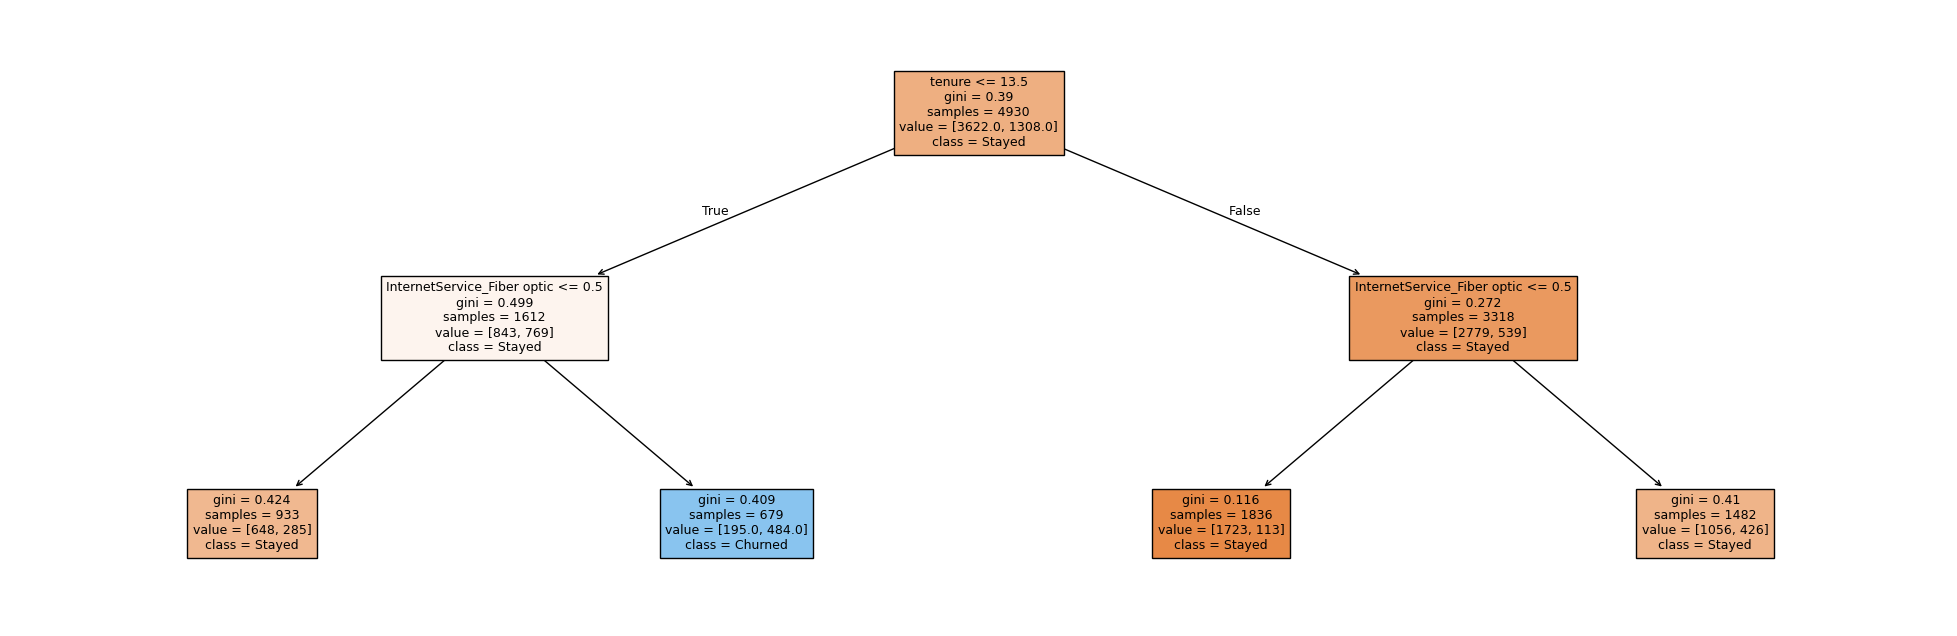

In [53]:
## Plot the tree
plt.figure(figsize=(25,8))
plot_tree(dt, feature_names=X_train.columns, class_names = ["Stayed", "Churned"], filled = True, fontsize=9);

In [54]:
## GINI
gini_root = 0.39
gini_left = 0.499
gini_right = 0.272
combined_gini = (1612/4930)*gini_left + (3318/4930)*gini_right

## IMPROVEMENT (GAIN, IMPURITY DECREASE)
gini_root - combined_gini

0.0437760649087221

In [55]:
from sklearn.metrics import recall_score

## PERFORMANCE
y_hat = dt.predict(X_test)

## 1) Accuracy
print(f'Accuracy on Test Set: {accuracy_score(y_test, y_hat)}')
print(f'Accuracy on Training Set: {accuracy_score(y_train, dt.predict(X_train))}')

## 2) Recall (Detection Rate) - How many customers who are likely to churn do we detect?
print(f'Detection on Test Set: {recall_score(y_test, y_hat)}')
print(f'Detection on Training Set: {recall_score(y_train, dt.predict(X_train))}')

Accuracy on Test Set: 0.7785139611926172
Accuracy on Training Set: 0.7933062880324544
Detection on Test Set: 0.3404634581105169
Detection on Training Set: 0.37003058103975534


## 2. Restricted vs. unrestricted decision trees

An unrestricted tree can grow many branches and fit the training data very closely. A restricted tree is simpler and may generalize better.

- `max_depth`: maximum number of splits along a path.
- `min_samples_split`: minimum observations required to attempt a split.
- `min_samples_leaf`: minimum observations in each leaf.

**Question:** Which tree do you expect to have higher *training* accuracy?

In [ ]:
# Fit two trees
full_tree = DecisionTreeClassifier(random_state=591)
small_tree = DecisionTreeClassifier(max_depth=3, random_state=591)

## TO DO: FIT THE TREES AND PRINT TRAIN AND TEST PERFORMANCE

In [ ]:
# Visualize only the first 3 levels to keep the plot readable
plt.figure(figsize=(17, 7))
plot_tree(small_tree, feature_names=X.columns, class_names=['No', 'Yes'],
          filled=True, fontsize=8)
plt.show()

**Interpret:** Does a better training score always mean a better test score? Which tree would you choose based on these results?

**Your answer:**

## 3. Experiment with `max_depth`

Try different depths and observe how training and test accuracy change. This is a **demonstration**: do not repeatedly choose hyperparameters based on the final test set in a real project. We will use cross-validation for tuning below.

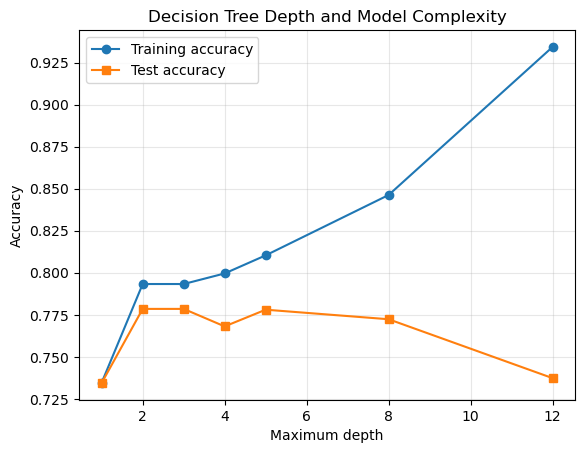

In [56]:
depths = [1, 2, 3, 4, 5, 8, 12]
train_accuracy = []
test_accuracy = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=591)
    tree.fit(X_train, y_train)
    train_accuracy.append(tree.score(X_train, y_train))
    test_accuracy.append(tree.score(X_test, y_test))

plt.plot(depths, train_accuracy, 'o-', label='Training accuracy')
plt.plot(depths, test_accuracy, 's-', label='Test accuracy')
plt.xlabel('Maximum depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Depth and Model Complexity')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Practice 3A

Change the list `depths` to `[2, 4, 6, 10, 15]` and rerun the plot.

1. What happens to training accuracy as depth increases?
2. Does test accuracy always increase?
3. Why might a deep tree overfit?

**Your answers:**

## 4. Other hyperparameters

The next two examples keep the code simple. Compare what happens when the minimum number of observations per leaf increases.

In [57]:
tree_leaf_1 = DecisionTreeClassifier(max_depth=6, min_samples_leaf=1, random_state=591)
tree_leaf_30 = DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=591)

tree_leaf_1.fit(X_train, y_train)
tree_leaf_30.fit(X_train, y_train)

print('min_samples_leaf=1  | leaves:', tree_leaf_1.get_n_leaves(),
      '| test accuracy:', round(tree_leaf_1.score(X_test, y_test), 3))
print('min_samples_leaf=30 | leaves:', tree_leaf_30.get_n_leaves(),
      '| test accuracy:', round(tree_leaf_30.score(X_test, y_test), 3))

min_samples_leaf=1  | leaves: 61 | test accuracy: 0.785
min_samples_leaf=30 | leaves: 53 | test accuracy: 0.791


**Practice 4A:** Change `min_samples_leaf=30` to `50`. Does the tree become larger or smaller? Why?

**Your answer:**

## 5. Grid Search with Cross-Validation

Instead of manually trying many values, `GridSearchCV` tests combinations of hyperparameters using cross-validation **within the training data**.

We will follow the simple approach used in class:

1. Define a parameter grid.
2. Create a `DecisionTreeClassifier`.
3. Create `GridSearchCV`.
4. Fit using `X_train, y_train`.
5. Inspect the best parameters and evaluate on `X_test`.

In [58]:
from sklearn.model_selection import GridSearchCV

## GRID with the options to check
### dictionary ---- {'criterion': ["gini", "entropy"], 'max_leaf_nodes': [10, 20, 40, 60]}
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 4, 6, None],
    'min_samples_split': [2, 20, 40]
}

# How many combinations will be evaluated?
print('Combinations:', 2 * 4 * 3)

Combinations: 24


### Practice 5A — Complete the Grid Search

Fill in the missing lines using `GridSearchCV` and `.fit()`. Use **5-fold cross-validation** and accuracy as the scoring metric.

In [59]:
## instance with no hyperparameters (defaults)
dt = DecisionTreeClassifier(random_state=591)

# TODO: create the grid search and fit it
dt_grid = GridSearchCV(dt, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=591),
             n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 4, 6, None],
                         'min_samples_split': [2, 20, 40]},
             scoring='accuracy')

### Practice 5B — Inspect the best model

After completing Practice 5A, uncomment the code below.

In [60]:
print('Best parameters:', dt_grid.best_params_)
print('Best cross-validation accuracy:', round(dt_grid.best_score_, 4))
best_tree = dt_grid.best_estimator_
print('Test accuracy:', round(best_tree.score(X_test, y_test), 4))

Best parameters: {'criterion': 'gini', 'max_depth': 6, 'min_samples_split': 20}
Best cross-validation accuracy: 0.7931
Test accuracy: 0.7861


**Interpret:** Why is cross-validation preferable to choosing the best depth by repeatedly checking the test set?

**Your answer:**

## 6. Compare the final models

Compare the unrestricted tree, restricted tree, and tuned tree on the same test set. Complete the grid search before running this cell.

In [ ]:
# TODO: uncomment after completing the grid search
# results = pd.DataFrame({
#     'Model': ['Unrestricted tree', 'Depth 3 tree', 'Grid Search tree'],
#     'Test Accuracy': [
#         full_tree.score(X_test, y_test),
#         small_tree.score(X_test, y_test),
#         best_tree.score(X_test, y_test)
#     ]
# })
# results

In [ ]:
# TODO: plot the confusion matrix for the tuned tree
# ConfusionMatrixDisplay.from_estimator(best_tree, X_test, y_test,
#                                     display_labels=['No churn', 'Churn'],
#                                     cmap='Blues')
# plt.show()

## 7. Optional: Cost-complexity pruning (`ccp_alpha`)

A larger `ccp_alpha` penalizes tree complexity more strongly. It often produces a smaller tree. This is optional because `max_depth` and `min_samples_leaf` already provide easy ways to control complexity.

In [ ]:
pruned_tree = DecisionTreeClassifier(ccp_alpha=0.005, random_state=591)
pruned_tree.fit(X_train, y_train)

print('Pruned tree leaves:', pruned_tree.get_n_leaves())
print('Pruned tree test accuracy:', round(pruned_tree.score(X_test, y_test), 3))

## Exit Ticket

1. What is the difference between a **parameter** and a **hyperparameter**?
2. What happens when `max_depth` increases?
3. What does `GridSearchCV` do?
4. Why should the final test set not be used to choose hyperparameters?

**Your answers:**